In [1]:

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import time
import pandas as pd

# Load MNIST dataset
(X_train, y_train), (X_test, y_test) = tf.keras.datasets.mnist.load_data()

# Normalize pixel values between 0 and 1
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)


Training data: (60000, 28, 28)
Testing data: (10000, 28, 28)


In [2]:
#Create the three models
def create_model(activation):
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(28, 28)),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(128, activation=activation, name="hidden1"),
        tf.keras.layers.Dense(64, activation=activation, name="hidden2"),
        tf.keras.layers.Dense(10, activation="softmax", name="output")
    ])

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

# Create models
models = {
    "Sigmoid": create_model("sigmoid"),
    "Tanh": create_model("tanh"),
    "ReLU": create_model("relu")
}

print("All three models are created.")


All three models are created.


In [3]:
#Train the models and record training time
histories = {}
training_times = {}

for name, model in models.items():
    print("Training", name, "model...")

    start = time.time()

    histories[name] = model.fit(
        X_train, y_train,
        epochs=10,
        batch_size=64,
        validation_split=0.2,
        verbose=1
    )

    training_times[name] = time.time() - start

    print(name, "training time:", round(training_times[name], 2), "seconds")

print("Training completed.")


Training Sigmoid model...
Epoch 1/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 9s 7ms/step - accuracy: 0.8369 - loss: 0.6956 - val_accuracy: 0.9222 - val_loss: 0.2833
Epoch 2/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.9290 - loss: 0.2472 - val_accuracy: 0.9419 - val_loss: 0.2024
Epoch 3/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.9464 - loss: 0.1814 - val_accuracy: 0.9530 - val_loss: 0.1642
Epoch 4/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.9587 - loss: 0.1405 - val_accuracy: 0.9606 - val_loss: 0.1386
Epoch 5/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9668 - loss: 0.1125 - val_accuracy: 0.9659 - val_loss: 0.1186
Epoch 6/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9737 - loss: 0.0915 - val_accuracy: 0.9682 - val_loss: 0.1075
Epoch 7/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.9779 - loss: 0.0757 - val_accuracy: 0.9703 - val_loss: 0.1012
Epoch 8/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.9821 - loss:

In [4]:
#Evaluate models on test data
test_results = {}

for name, model in models.items():
    loss, accuracy = model.evaluate(X_test, y_test, verbose=0)

    test_results[name] = {
        "Test Loss": loss,
        "Test Accuracy": accuracy
    }

    print(name)
    print("Test Loss:", round(loss, 4))
    print("Test Accuracy:", round(accuracy * 100, 2), "%")
    print()


Sigmoid
Test Loss: 0.0789
Test Accuracy: 97.46 %

Tanh
Test Loss: 0.0854
Test Accuracy: 97.43 %

ReLU
Test Loss: 0.0942
Test Accuracy: 97.42 %



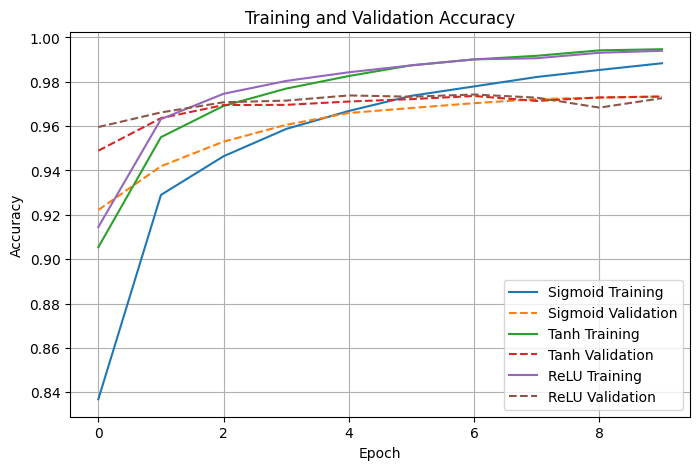

In [6]:
#Plot training and validation accuracy
plt.figure(figsize=(8, 5))

for name, history in histories.items():
    plt.plot(history.history["accuracy"], label=name + " Training")
    plt.plot(history.history["val_accuracy"], linestyle="--",
             label=name + " Validation")

plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()


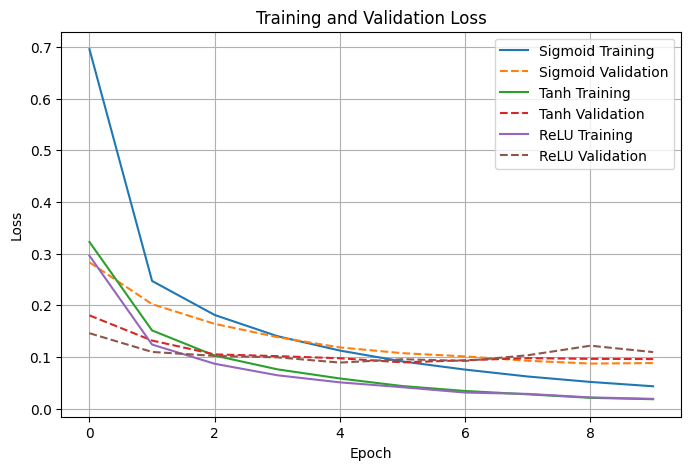

In [7]:
#Plot training and validation loss
plt.figure(figsize=(8, 5))

for name, history in histories.items():
    plt.plot(history.history["loss"], label=name + " Training")
    plt.plot(history.history["val_loss"], linestyle="--",
             label=name + " Validation")

plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()


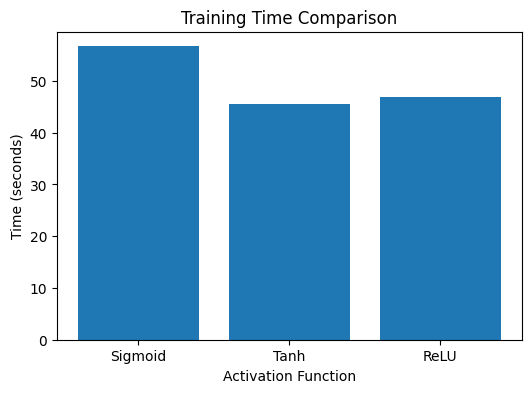

In [8]:
#Compare training time
plt.figure(figsize=(6, 4))

plt.bar(training_times.keys(), training_times.values())

plt.title("Training Time Comparison")
plt.xlabel("Activation Function")
plt.ylabel("Time (seconds)")
plt.show()


In [9]:
#Measure gradient flow in different layers
gradient_results = {}

# Use a small batch of training images
x_sample = X_train[:128]
y_sample = y_train[:128]

for name, model in models.items():

    with tf.GradientTape() as tape:
        predictions = model(x_sample, training=True)
        loss = tf.reduce_mean(
            tf.keras.losses.sparse_categorical_crossentropy(
                y_sample, predictions
            )
        )

    # Get weights of the three Dense layers
    kernels = [
        model.get_layer("hidden1").kernel,
        model.get_layer("hidden2").kernel,
        model.get_layer("output").kernel
    ]

    gradients = tape.gradient(loss, kernels)

    # Calculate mean absolute gradient
    gradient_results[name] = [
        float(tf.reduce_mean(tf.abs(g)).numpy())
        for g in gradients
    ]

print("Gradient magnitudes:")
for name, values in gradient_results.items():
    print(name, ":", [round(v, 8) for v in values])


Gradient magnitudes:
Sigmoid : [6.815e-05, 0.00042021, 0.00116682]
Tanh : [0.00013221, 0.00068182, 0.00126433]
ReLU : [0.00031817, 0.00094897, 0.00238314]


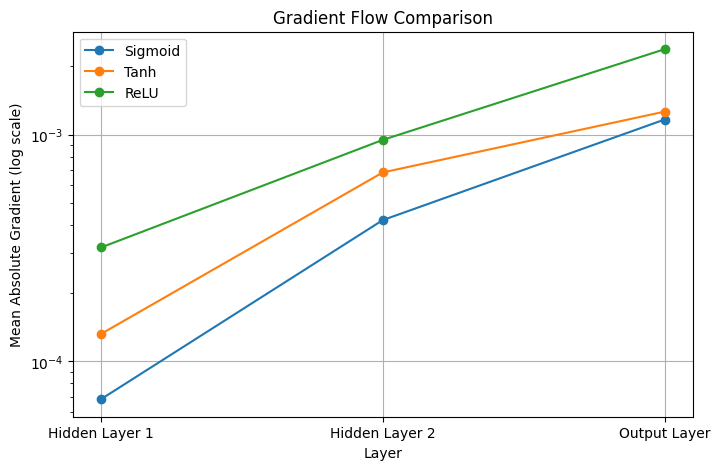

In [10]:
#Plot gradient flow
layers_name = ["Hidden Layer 1", "Hidden Layer 2", "Output Layer"]

plt.figure(figsize=(8, 5))

for name, values in gradient_results.items():
    # Small positive value allows zero gradients to appear on log scale
    values = [max(v, 1e-12) for v in values]
    plt.plot(layers_name, values, marker="o", label=name)

plt.yscale("log")
plt.title("Gradient Flow Comparison")
plt.xlabel("Layer")
plt.ylabel("Mean Absolute Gradient (log scale)")
plt.legend()
plt.grid(True)
plt.show()


In [11]:
#Final comparison table
results = []

for name, history in histories.items():
    results.append({
        "Activation": name,
        "Training Time (s)": round(training_times[name], 2),
        "Training Accuracy (%)": round(
            history.history["accuracy"][-1] * 100, 2
        ),
        "Validation Accuracy (%)": round(
            history.history["val_accuracy"][-1] * 100, 2
        ),
        "Test Accuracy (%)": round(
            test_results[name]["Test Accuracy"] * 100, 2
        ),
        "Training Loss": round(history.history["loss"][-1], 4),
        "Validation Loss": round(history.history["val_loss"][-1], 4),
        "Test Loss": round(test_results[name]["Test Loss"], 4),
        "Gradient Hidden 1": gradient_results[name][0],
        "Gradient Hidden 2": gradient_results[name][1],
        "Gradient Output": gradient_results[name][2]
    })

df = pd.DataFrame(results)
display(df)


,Activation,Training Time (s),Training Accuracy (%),Validation Accuracy (%),Test Accuracy (%),Training Loss,Validation Loss,Test Loss,Gradient Hidden 1,Gradient Hidden 2,Gradient Output
0,Sigmoid,56.69,98.83,97.33,97.46,0.0435,0.0884,0.0789,0.000068,0.000420,0.001167
1,Tanh,45.63,99.47,97.33,97.43,0.0184,0.0961,0.0854,0.000132,0.000682,0.001264
2,ReLU,46.93,99.40,97.26,97.42,0.0192,0.1096,0.0942,0.000318,0.000949,0.002383


In [12]:
#Print a simple observation
print("OBSERVATIONS")

for name in models:
    print("\n", name)
    print("Training time:", round(training_times[name], 2), "seconds")
    print("Test accuracy:",
          round(test_results[name]["Test Accuracy"] * 100, 2), "%")
    print("Gradient magnitudes:",
          [round(v, 8) for v in gradient_results[name]])

print("\nStudy the gradient plot:")
print("- Very small gradients in earlier layers may indicate vanishing gradients.")
print("- ReLU can have inactive neurons when their outputs remain zero.")
print("- Compare the measured results; do not assume one activation is always best.")


OBSERVATIONS

 Sigmoid
Training time: 56.69 seconds
Test accuracy: 97.46 %
Gradient magnitudes: [6.815e-05, 0.00042021, 0.00116682]

 Tanh
Training time: 45.63 seconds
Test accuracy: 97.43 %
Gradient magnitudes: [0.00013221, 0.00068182, 0.00126433]

 ReLU
Training time: 46.93 seconds
Test accuracy: 97.42 %
Gradient magnitudes: [0.00031817, 0.00094897, 0.00238314]

Study the gradient plot:
- Very small gradients in earlier layers may indicate vanishing gradients.
- ReLU can have inactive neurons when their outputs remain zero.
- Compare the measured results; do not assume one activation is always best.
